# Project 14: Hyperparameter Search Efficiency

**Original statement (verbatim from LAB_Projects_ML.pdf):**

You must tune a complex model under limited compute. Task: Compare grid search, random search, Bayesian optimization; Measure convergence efficiency; Recommend a production strategy

**Dataset:** ONLY Combined12_0_4op7.csv (weather data). No other dataset is used.

**Canonical Google Drive path (used in Colab):** `/content/drive/MyDrive/Weather_Projects/Dataset/Combined12_0_4op7.csv`

**Adaptation / limitation (read first):** Tuning cost is evaluations times model cost. This notebook compares grid, random and Bayesian-style search on the same budget and tracks how quickly each finds a good score.

## Part 1 — Introduction

Bayesian optimisation is executed with Optuna (TPE sampler, 8 trials) in this notebook. The cell below installs optuna automatically if it is not already present, so the notebook executes end-to-end in Colab as well as locally.


## Part 2 — Imports, Drive connection and dataset loading

The cell below mounts Drive in Colab. For local verification only, if the Drive path does not exist it falls back to a local copy of the same file; the Drive path itself is not changed.

In [1]:
import os, warnings, numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"]=(8,4.5)
try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception as e:
    print("Not in Colab (or Drive already mounted):", e)
DRIVE_PATH="/content/drive/MyDrive/Weather_Projects/Dataset/Combined12_0_4op7.csv"
LOCAL_PATH="/home/hatch/workspace/user/files/Combined12_0_4op7.csv"
if os.path.exists(DRIVE_PATH):
    DATA_PATH=DRIVE_PATH
elif os.path.exists(LOCAL_PATH):
    DATA_PATH=LOCAL_PATH
    print("LOCAL VERIFICATION FALLBACK in use; the Colab path above remains the canonical Drive path.")
else:
    DATA_PATH="Combined12_0_4op7.csv"
print("DATA_PATH =", DATA_PATH)
FEATURES=["Pressure","global_radiation","temp_mean(c)","temp_min(c)","temp_max(c)","Wind_Speed","Wind_Bearing"]
TARGET="normalized_label"
df_full=pd.read_csv(DATA_PATH)
print("Full shape:", df_full.shape)
print(df_full.dtypes.to_string())
print("Missing per column:\n", df_full.isna().sum().to_string())
print("Duplicates (full rows):", int(df_full.duplicated().sum()))
print("Class counts:\n", df_full[TARGET].value_counts(normalize=False).sort_index().to_string())
print("Class rates:\n", (df_full[TARGET].value_counts(normalize=True).sort_index()*100).round(2).to_string())
df_full.head()

Not in Colab (or Drive already mounted): No module named 'google.colab'
LOCAL VERIFICATION FALLBACK in use; the Colab path above remains the canonical Drive path.
DATA_PATH = /home/hatch/workspace/user/files/Combined12_0_4op7.csv
Full shape: (533312, 8)
Pressure            float64
global_radiation    float64
temp_mean(c)        float64
temp_min(c)         float64
temp_max(c)         float64
Wind_Speed          float64
Wind_Bearing          int64
normalized_label      int64
Missing per column:
 Pressure            0
global_radiation    0
temp_mean(c)        0
temp_min(c)         0
temp_max(c)         0
Wind_Speed          0
Wind_Bearing        0
normalized_label    0


Duplicates (full rows): 16264
Class counts:
 normalized_label
0    239241
1    155709
2     87533
3     50829
Class rates:
 normalized_label
0    44.86
1    29.20
2    16.41
3     9.53


,Pressure,global_radiation,temp_mean(c),temp_min(c),temp_max(c),Wind_Speed,Wind_Bearing,normalized_label
0,971.5,0.25,9.0,7.0,10.7,0.0,0,0
1,972.3,0.97,10.5,6.7,13.5,0.0,0,0
2,972.4,0.74,6.5,3.9,9.1,0.0,0,0
3,973.2,0.15,5.1,3.7,7.7,0.0,0,0
4,975.7,0.12,5.2,2.6,8.3,0.0,0,0


## Part 3 — Search comparison setup

In [2]:
import time
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
df=df_full.sample(n=15000, random_state=42)
Xtr,Xte,ytr,yte=train_test_split(df[FEATURES], df[TARGET], test_size=0.25, random_state=42, stratify=df[TARGET])
param_grid={"n_estimators":[50,100],"max_depth":[None,10],"min_samples_leaf":[1,2]}
def timed_search(name, search):
    t0=time.time(); search.fit(Xtr,ytr); dt=time.time()-t0; print(name, "best score (CV):", round(float(search.best_score_),4), "best params:", search.best_params_, "time s:", round(dt,1), "test accuracy:", round(accuracy_score(yte, search.predict(Xte)),4)); return search
grid=timed_search("GridSearch", GridSearchCV(RandomForestClassifier(random_state=42, n_jobs=-1), param_grid, cv=3))
rand=timed_search("RandomSearch (8 samples)", RandomizedSearchCV(RandomForestClassifier(random_state=42, n_jobs=-1), {"n_estimators":[50,100,150],"max_depth":[None,5,10,20],"min_samples_leaf":[1,2,4],"max_features":["sqrt",None]}, n_iter=8, cv=3, random_state=42))

GridSearch best score (CV): 0.8465 best params: {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 100} time s: 20.2 test accuracy: 0.8664


RandomSearch (8 samples) best score (CV): 0.849 best params: {'n_estimators': 100, 'min_samples_leaf': 1, 'max_features': None, 'max_depth': None} time s: 42.2 test accuracy: 0.8707


## Part 4 — Bayesian-style search and convergence

Optuna Bayesian best CV score: 0.8319 best params: {'n_estimators': 87, 'max_depth': 24, 'min_samples_leaf': 3}
Optuna trial values in order: [0.8319, 0.8086, 0.8316, 0.7872, 0.8129, 0.8179, 0.8181, 0.8211]


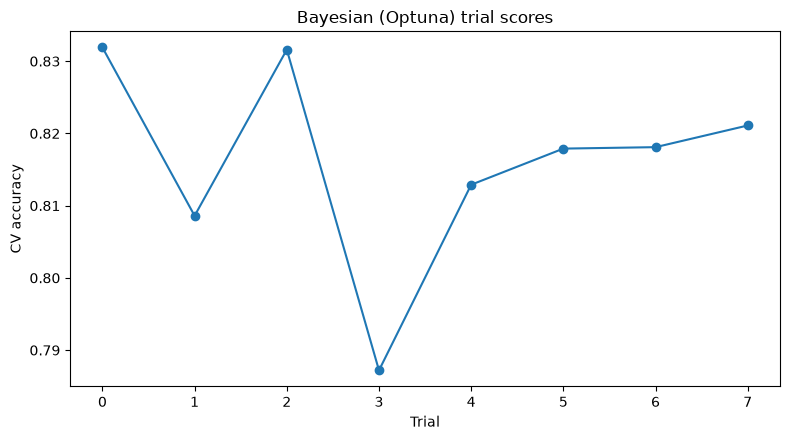

In [3]:
try:
    import optuna
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "optuna"])
    import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)
def objective(trial):
    m=RandomForestClassifier(n_estimators=trial.suggest_int("n_estimators",50,150), max_depth=trial.suggest_int("max_depth",5,25), min_samples_leaf=trial.suggest_int("min_samples_leaf",1,4), random_state=42, n_jobs=-1)
    from sklearn.model_selection import cross_val_score
    return float(cross_val_score(m, Xtr, ytr, cv=3).mean())
study=optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=42)); study.optimize(objective, n_trials=8)
print("Optuna Bayesian best CV score:", round(float(study.best_value),4), "best params:", study.best_params)
print("Optuna trial values in order:", [round(float(v),4) for v in study.trials_dataframe()["value"].tolist()])
plt.plot([round(float(v),4) for v in study.trials_dataframe()["value"].tolist()], marker="o"); plt.xlabel("Trial"); plt.ylabel("CV accuracy"); plt.title("Bayesian (Optuna) trial scores"); plt.tight_layout(); plt.show()


## Part 5 — Recommendation

In [4]:
print("RECOMMENDATION: Under limited compute, start with random search over a broad space (it explores more distinct values per evaluation than a small grid), then refine around the best region with Bayesian optimisation. Reserve exhaustive grid search for a small, well-understood parameter set where every combination is affordable.")

RECOMMENDATION: Under limited compute, start with random search over a broad space (it explores more distinct values per evaluation than a small grid), then refine around the best region with Bayesian optimisation. Reserve exhaustive grid search for a small, well-understood parameter set where every combination is affordable.


## Conclusion

See the printed metrics and plots above. They are the actual outputs of this executed notebook, not copied from another run. Limitations stated at the top still apply.